Raw Trace Rendering
===================

This notebook contains code rendering raw (time-domain) measurement traces. Some of these plots ended up in the paper.

Imports and setup stuff
-----------------------

The following cells contain code loading the measurement data.

In [2]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35, 41, 42, 43, 44, 45],
    'short_within_trace': [26, 27, 28, 29, 30, 46, 47, 48, 49, 50],
    'open': [21, 22, 23, 24, 25, 36, 37, 38, 39, 40],
    'probe_points': [53, 54, 55],
    'loop_patch': [56, 57, 58, 59, 60, 61, 62, 63, 64, 65],
}

baseline_serials = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    data_dict_runs = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            info['baseline'] = (serial in baseline_serials)
            data_dict[mesh_id].append(data)
            data_dict_runs[meta.strip()].append(data)
    return data_dict, data_dict_runs

data, data_runs = load_multichannel_data()

/tmp/ipykernel_129399/2846935186.py:45: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_129399/2846935186.py:45: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [4]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [6, 7, 8, 9, 10]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}

{('open', 0.3): ['simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3',
  'simple-attack-25-07-07-01-p0.3'],
 ('open', 0.4): ['simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4',
  'simple-attack-25-07-07-01-p0.4'],
 ('open', 0.6): ['mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6'],
 ('open', 1.0): ['mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
 

In [5]:
color_palette = [(181/255, 0.0, 0.0), (1.0, 102/255, 0.0), (0.0, 92/255, 148/255)]

def view_trace(trace, xlim=(160, 450), ylim=None, axs=None, select_load=('open', 'load', 'short'), color=None, alpha=None, plot_variance=True, normalize=False, cal=False, smooth=None, directions=('fwd', 'flip'), adcs=('adc1', 'adc2'), scale_time=False, yscale=1):
    if axs is None:
        fig, axs = plt.subplots(2, 2, figsize=(18, 4))
        fig.suptitle(trace['info']['specimen'])
    sampling_period_ns = 1000 / 168 / 32
    for i, direction in enumerate(directions):
        for j, adc in enumerate(adcs):
            axs[i, j].grid()
            a, b = xlim
            #if scale_time:
            #    axs[i,j].set_xlim([a, b])
            #else:
            #    axs[i,j].set_xlim([a*sampling_period_ns, b*sampling_period_ns])
            min_y = 1e9
            max_y = -1e9
            if color:
                palette = (color, color, color)
            else:
                palette = color_palette
            for color, load in zip(palette, ['open', 'short', 'load']):
                if load not in select_load:
                    continue
                adc_trace = np.array(trace['data'][f'{load}_{direction}'][adc])
                var_trace = np.array(trace['data'][f'{load}_{direction}'][adc.replace('adc', 'var')])

                if cal:
                    cal_trace = np.array(trace['data']['cal'][adc])
                    
                    if smooth is not None:
                        t = np.linspace(0, 1, len(adc_trace))
                        spl = interpolate.make_smoothing_spline(t, cal_trace, lam=smooth)
                        cal_trace = spl(t)
                    
                    adc_trace -= cal_trace
                
                if smooth is not None:
                    t = np.linspace(0, 1, len(adc_trace))
                    spl = interpolate.make_smoothing_spline(t, adc_trace, lam=smooth)
                    adc_trace = spl(t)
                
                if normalize:
                    adc_trace -= adc_trace[a:b].mean()
                if scale_time:
                    t = np.linspace(0, sampling_period_ns*len(adc_trace), len(adc_trace))
                else:
                    t = np.linspace(0, len(adc_trace)-1, len(adc_trace))

                adc_trace *= yscale
                var_trace *= yscale
                min_y = min(min_y, (adc_trace - var_trace)[a:b].min())
                max_y = max(max_y, (adc_trace + var_trace)[a:b].max())
                axs[i,j].plot(t, adc_trace, color=color, alpha=alpha, label=f'{direction} {adc}')
                if plot_variance:
                    axs[i,j].fill_between(t, adc_trace + var_trace, adc_trace - var_trace, color=color, alpha=0.3*alpha)
            dy = max_y - min_y
            #if ylim:
            #    axs[i,j].set_ylim(ylim)
            #else:
            #    axs[i, j].set_ylim([min_y - 0.1*dy, max_y + 0.1*dy])

#view_trace(mod_modified[('short_within_trace', 0.3)][0])
#view_trace(mod_modified[('short_within_trace', 0.3)][1])
#view_trace(mod_modified[('short_within_trace', 0.3)][2])
#view_trace(mod_modified[('short_within_trace', 0.3)][3])
#view_trace(mod_modified[('short_within_trace', 0.3)][4])

Plot Temperature Delta Test Run
-------------------------------

This cell exports the plot visualizing the effect of heating the mesh on the measurement. The output plot is manually edited in Inkscape to add the labels and arrows.

0.22803859710693353


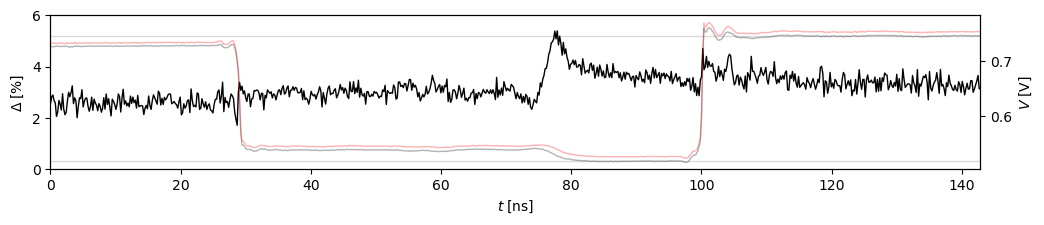

In [11]:
fig, ax = plt.subplots(figsize=(12, 2))
trace_a = np.array(group_baseline[0]['data']['open_fwd']['adc1'])
trace_b = np.array(group_hot[0]['data']['open_fwd']['adc1'])
high_a = sorted(trace_a)[-int(len(trace_a)*0.1)]
low_a = sorted(trace_a)[int(len(trace_a)*0.1)]
ampl_a = abs(high_a - low_a)
print(ampl_a)
delta = (trace_b - trace_a) / ampl_a * 100

sampling_period_ns = 1000 / 168 / 32
t = np.linspace(0, len(trace_a)*sampling_period_ns, len(trace_a))
#spl = interpolate.make_smoothing_spline(t, delta, lam=1e-3)
#delta = spl(t)

ax.plot(t, delta, color='black', linewidth=1)
tx = ax.twinx()
tx.plot(t, trace_a, color='black', alpha=0.3, zorder=-2, linewidth=1)
tx.plot(t, trace_b, color='red', alpha=0.3, zorder=-2, linewidth=1)
tx.axhline(low_a, color='black', alpha=0.15, zorder=-3, linewidth=1)
tx.axhline(high_a, color='black', alpha=0.15, zorder=-3, linewidth=1)
ax.set_xlabel(r'$t\;[\mathrm{ns}]$')
ax.set_ylabel(r'$\Delta\;[\mathrm{\%}]$')
tx.set_ylabel(r'$V\;[\mathrm{V}]$')
ax.set_xlim([0, max(t)])
ax.set_ylim([0, 6])
fig.savefig('../../paper/fig_tempco_raw.svg')

Test Plots
----------

These are test plots of complete measurement series (forward and backward, both P and N channels, with load/open/short loads).

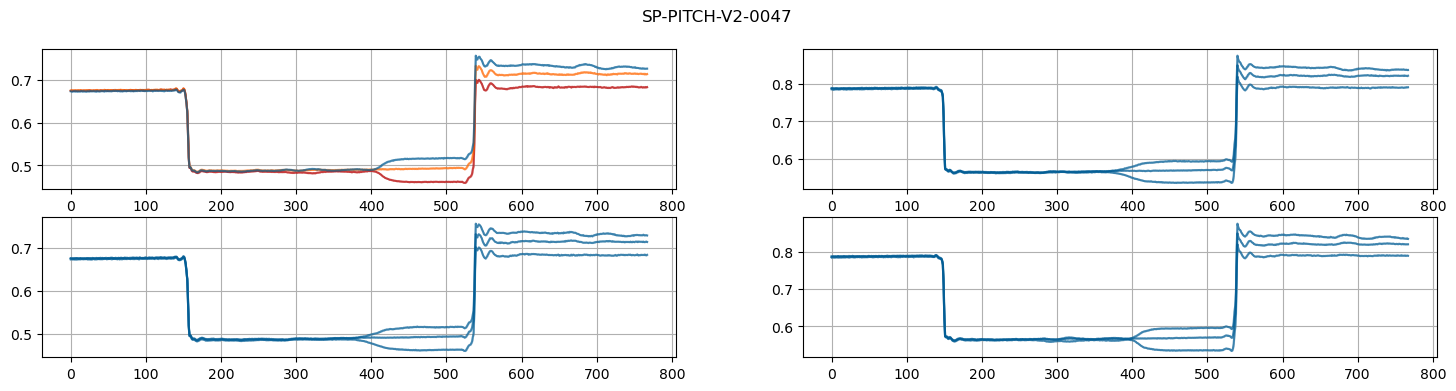

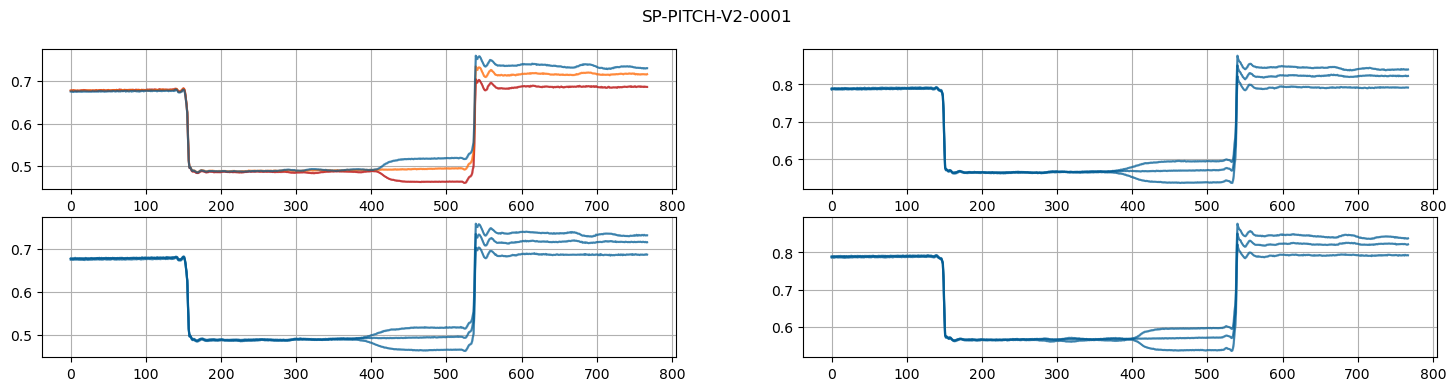

In [14]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = sorted([value for value in entries if not value['info']['mods']], key=lambda value: value['info']['serial'])
group_modified = sorted([value for value in entries if value['info']['mods']], key=lambda value: value['info']['serial'])

view_trace(group_modified[6], alpha=.7)
view_trace(group_baseline[0], alpha=.7)

{'meta': 'probe-interleave-25-07-02-01-p0.3', 'specimen': 'SP-PITCH-V2-0010', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-02T13:57:32.799Z', 'mods': [], 'mesh_id': 'M-SP-PITCH-V2-0010-0.3', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.3', 'serial': 10, 'baseline': True}
{'meta': 'baseline-repeat-25-07-02-02-p0.3', 'specimen': 'SP-PITCH-V2-0010', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-02T16:43:09.787Z', 'mods': [], 'mesh_id': 'M-SP-PITCH-V2-0010-0.3', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.3', 'serial': 10, 'baseline': True}


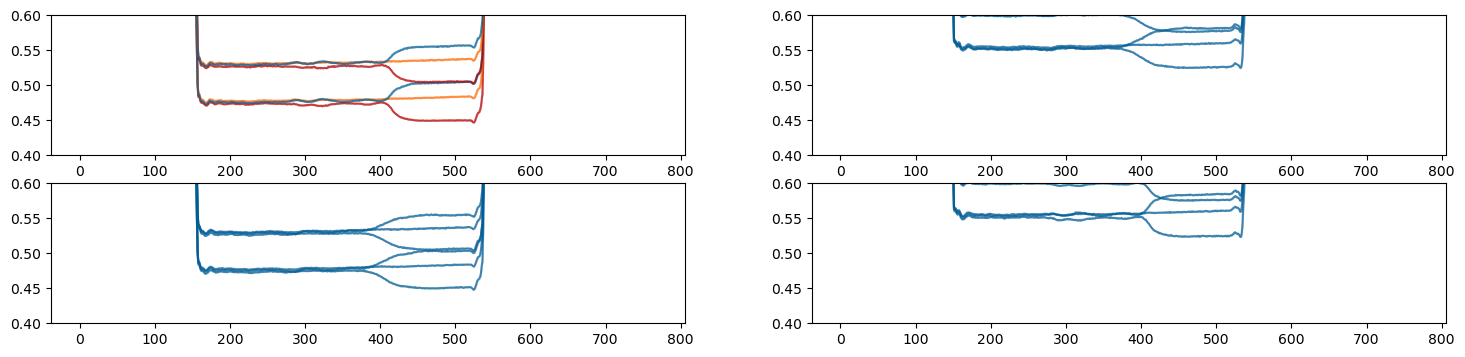

In [15]:
group_a = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:10]
group_b = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-02-p0.3']
print(group_a[0]['info'])
print(group_b[0]['info'])
fig, axs = plt.subplots(2, 2, figsize=(18, 4))
view_trace(group_a[0], axs=axs, alpha=0.7)
view_trace(group_b[0], axs=axs, alpha=0.7)
for ax in axs.flatten():
    ax.set_ylim([0.4, 0.6])

[56, 57, 58, 60, 61, 62, 63, 65]
10


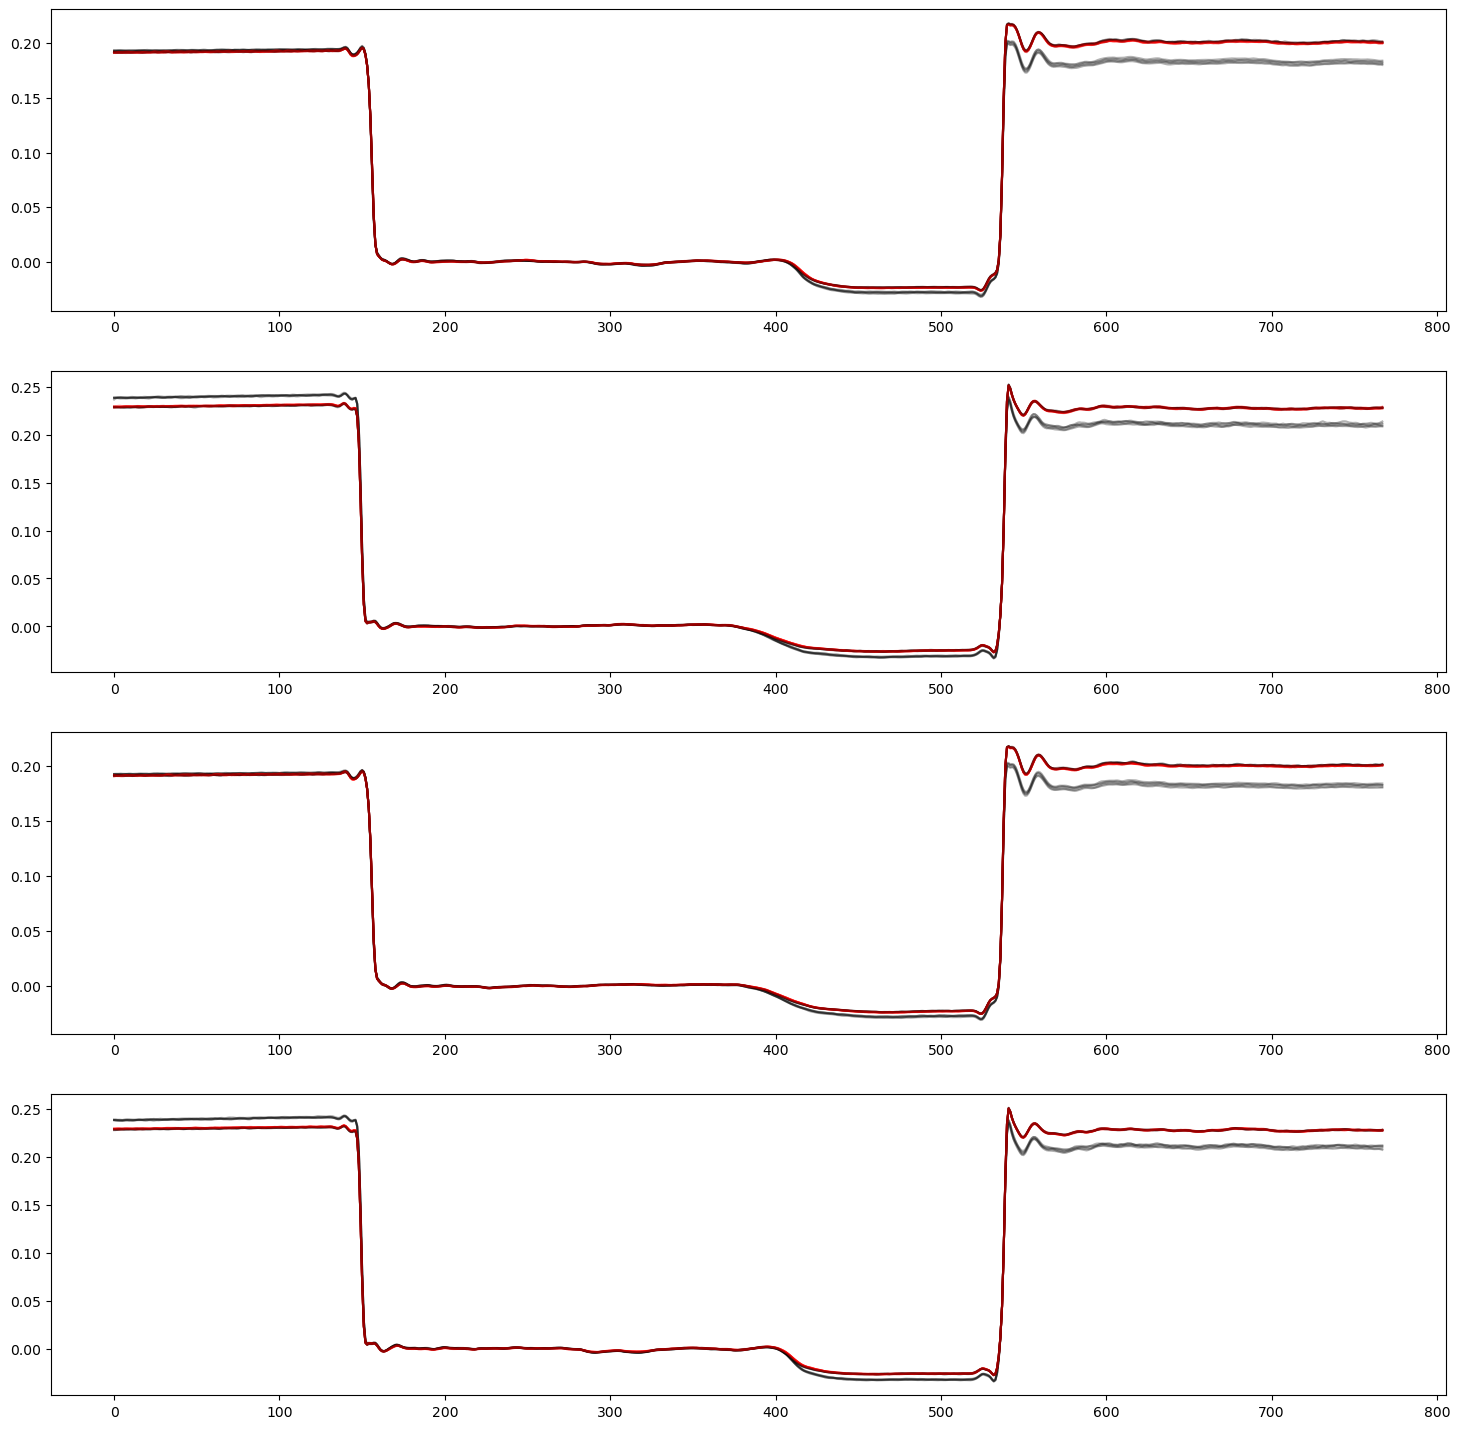

In [16]:
#group_a = [value for value in data_runs[f'patch-at#ck-25-07-09-01-p0.3'] if not value['info']['mods']]
# We have a hidden short somewhere in sample 64. I wasn't able to quickly fix it.
#group_b = [value for value in data_runs[f'patch-attack-25-07-09-01-p0.3'] if 'loop_patch' in value['info']['mods'] and value['info']['serial'] != 64]

group_a = [value for value in data_runs[f'attack-repeat-25-07-09-01-p0.3'] if not value['info']['mods']]
print(sorted(set([value['info']['serial'] for value in data_runs[f'attack-repeat-25-07-09-01-p0.3'] if value['info']['mods']])))
group_b = [value for value in data_runs[f'attack-repeat-25-07-09-01-p0.3'] if 'loop_patch' in value['info']['mods'] and value['info']['serial'] == 63]
print(len(group_b))

fig, axs = plt.subplots(4, 1, figsize=(18, 18))
axs = axs.reshape((2, 2))
for i, trace in enumerate([x for t in zip(group_a[:5] + group_a[-5:], group_b) for x in t]):
    view_trace(trace, axs=axs, color=('red' if i%2 else 'black'), alpha=0.3, plot_variance=False, normalize=True, cal=False, select_load='open', xlim=(160, 400), smooth=1e-9)

for ax in axs.flatten():
    #ax.set_ylim([0.4, 0.5])
    pass

Patching Attack Difference Plots
--------------------------------

These plots visualize the time-domain difference between batches of measurement series taken from attack and reference specimens.

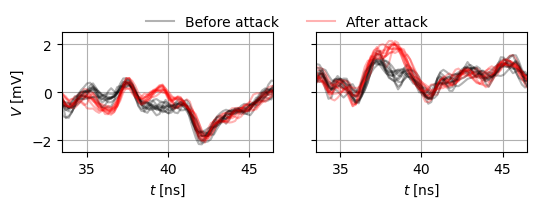

In [18]:
group_a1 = [value for value in data_runs[f'apply-patch-interleave-reference-25-07-11-03-p0.3'] if value['info']['serial'] != 74]
group_b1 = [value for value in data_runs[f'apply-patch-interleave-reference-25-07-11-03-p0.3'] if value['info']['serial'] == 74]
group_a2 = [value for value in data_runs[f'apply-patch-interleave-modified-25-07-11-03-p0.3'] if value['info']['serial'] != 74]
group_b2 = [value for value in data_runs[f'apply-patch-interleave-modified-25-07-11-03-p0.3'] if value['info']['serial'] == 74]

fig, axs = plt.subplots(1, 2, figsize=(6, 2), sharey=True)
axs = axs.reshape((1, 2))

for i, trace in enumerate([x for t in zip(group_b1, group_b2) for x in t]):
    view_trace(trace, axs=axs, color=('red' if i%2 else 'black'), alpha=0.3, plot_variance=False, normalize=True, cal=False, xlim=(160, 400), select_load='open', smooth=1e-9, directions=('flip',), scale_time=True, yscale=1e3)

sampling_period_ns = 1000 / 168 / 32
for ax in axs.flatten():
    ax.set_xlim([180*sampling_period_ns, 250*sampling_period_ns])
    ax.grid()
    ax.set_xlabel(r'$t\;[\text{ns}]$')
axs[0,0].set_ylim([-2.5, 2.5])
axs[0,0].set_ylabel(r'$V\;[\text{mV}]$')

handles, _labels = axs[0,0].get_legend_handles_labels()
fig.subplots_adjust(top=0.8, bottom=0.2)
fig.legend(handles[:2], ['Before attack', 'After attack'], loc='upper center', ncol=4, bbox_to_anchor=[0.5, 0.95], frameon=False)
fig.savefig('../../paper/fig_drill_mod_shape_new.pdf')